In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint,ReduceLROnPlateau
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    Concatenate,
    BatchNormalization
)

MAX_NB_WORDS = 20000
MAX_SEQUENCE_LENGTH = 100
EMBEDDING_DIM = 300

In [ ]:
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip -O /content/wiki-news-300d-1M.vec.zip
!unzip -q /content/wiki-news-300d-1M.vec.zip -d /content/
!ls -lh /content/wiki-news-300d-1M.vec

--2026-06-26 14:10:16--  https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 3.163.189.108, 3.163.189.96, 3.163.189.14, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|3.163.189.108|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 681808098 (650M) [application/zip]
Saving to: ‘/content/wiki-news-300d-1M.vec.zip’

/content/wiki-news- 100%[===================>] 650.22M  51.8MB/s    in 13s     

2026-06-26 14:10:29 (50.6 MB/s) - ‘/content/wiki-news-300d-1M.vec.zip’ saved [681808098/681808098]

-rw-r--r-- 1 root root 2.2G Mar 14  2018 /content/wiki-news-300d-1M.vec


In [ ]:
train_df = pd.read_csv("train_preprocessed.csv")
valid_df = pd.read_csv("valid_preprocessed.csv")
test_df = pd.read_csv("test_preprocessed.csv")

In [ ]:
text_columns = ["Statement","Subjects","Speaker","Speaker_Job","State","Party","Context"]

for df in [train_df, valid_df, test_df]:
    df["Combined_Text"] = (df[text_columns].fillna("").agg(" ".join, axis=1))

In [ ]:
binary_map = {"pants-fire":0,"false":0,"barely-true":0,"half-true":1,"mostly-true":1,"true":1}

for df in [train_df, valid_df, test_df]:
    df["Label"] = (df["Label"].astype(str).str.lower().str.strip())

y_train = train_df["Label"].map(binary_map)
y_valid = valid_df["Label"].map(binary_map)
y_test = test_df["Label"].map(binary_map)

In [ ]:
CREDIT_COLS = ["Barely_True_Count","False_Count","Half_True_Count","Mostly_True_Count", "Pants_On_fire_Count"]

X_train_credit = train_df[CREDIT_COLS].fillna(0).values
X_valid_credit  = valid_df[CREDIT_COLS].fillna(0).values
X_test_credit   = test_df[CREDIT_COLS].fillna(0).values

print("Credit features shape: ",X_train_credit.shape)

scaler = StandardScaler()
X_train_credit = scaler.fit_transform(X_train_credit)
X_valid_credit  = scaler.transform(X_valid_credit)
X_test_credit   = scaler.transform(X_test_credit)

CREDIT_DIM = X_train_credit.shape[1]

Credit features shape:  (10138, 5)


In [ ]:
tokenizer = Tokenizer(num_words=MAX_NB_WORDS,oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["Combined_Text"])
word_index = tokenizer.word_index

print("Vocabulary Size:", len(word_index))

train_sequences = tokenizer.texts_to_sequences(train_df["Combined_Text"])
valid_sequences = tokenizer.texts_to_sequences(valid_df["Combined_Text"])
test_sequences = tokenizer.texts_to_sequences(test_df["Combined_Text"])

X_train = pad_sequences(train_sequences,maxlen=MAX_SEQUENCE_LENGTH,padding="post",truncating="post")
X_valid = pad_sequences(valid_sequences,maxlen=MAX_SEQUENCE_LENGTH,padding="post",truncating="post")
X_test = pad_sequences(test_sequences,maxlen=MAX_SEQUENCE_LENGTH,padding="post",truncating="post")

Vocabulary Size: 15199


In [ ]:
FASTTEXT_PATH = "wiki-news-300d-1M.vec"

def load_fasttext(filepath, word_index):
    embeddings = {}

    with open(filepath,"r",encoding="utf-8",errors="ignore") as f:
        next(f)
        for line in f:
            values = line.rstrip().split(" ")
            word = values[0]
            if word in word_index:
                embeddings[word] = np.asarray(values[1:],dtype="float32")

    return embeddings

fasttext_embeddings = load_fasttext(FASTTEXT_PATH,word_index)
vocab_size = len(word_index) + 1
embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM))

for word, idx in word_index.items():
    vector = fasttext_embeddings.get(word)
    if vector is not None:
        embedding_matrix[idx] = vector

embedding_layer = Embedding(input_dim=vocab_size,output_dim=EMBEDDING_DIM,weights=[embedding_matrix],trainable=True)

In [ ]:
class_weights = compute_class_weight(class_weight="balanced",classes=np.unique(y_train),y=y_train)
class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(1.1416666666666666), 1: np.float64(0.8896103896103896)}


In [ ]:
text_input = Input(shape=(MAX_SEQUENCE_LENGTH,))
embedded = embedding_layer(text_input)

conv2 = Conv1D(128,2,activation="relu")(embedded)
conv3 = Conv1D(128,3,activation="relu")(embedded)
conv4 = Conv1D(128,4,activation="relu")(embedded)
conv5 = Conv1D(128,5,activation="relu")(embedded)
conv6 = Conv1D(128,6,activation="relu")(embedded)

pool2 = GlobalMaxPooling1D()(conv2)
pool3 = GlobalMaxPooling1D()(conv3)
pool4 = GlobalMaxPooling1D()(conv4)
pool5 = GlobalMaxPooling1D()(conv5)
pool6 = GlobalMaxPooling1D()(conv6)

credit_input = Input(shape=(CREDIT_DIM,), name="credit_input")
cred = Dense(32, activation="relu",kernel_regularizer=l2(1e-4))(credit_input)
cred = BatchNormalization()(cred)
cred = Dropout(0.3)(cred)
cred = Dense(16, activation="relu")(cred)

merged = Concatenate()([pool2, pool3, pool4, pool5, pool6, cred])

x = Dense(128,activation="relu")(merged)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(64,activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

output = Dense(2,activation="softmax")(x)

model = Model(inputs=[text_input, credit_input],outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3,weight_decay=1e-4,clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ credit_input        │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        192 │ credit_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 300)  │  4,560,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32)        │        128 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 99, 128)   │     76,928 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 98, 128)   │    115,328 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 97, 128)   │    153,728 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 96, 128)   │    192,128 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 95, 128)   │    230,528 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_1[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_2[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_3[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_4[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        528 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 656)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
│                     │                   │            │ dense_1[0][0]   

 Total params: 5,422,738 (20.69 MB)

 Trainable params: 5,422,290 (20.68 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_stop = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
checkpoint = ModelCheckpoint("best_binary_fasttext_cnn.keras",save_best_only=True,monitor="val_accuracy")
lr_plateau = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-6,verbose=1)

history = model.fit([X_train, X_train_credit],y_train,
    validation_data=([X_valid, X_valid_credit],y_valid),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop,checkpoint,lr_plateau])

model.save("binary_fasttext_cnn.keras")

Epoch 1/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 36s 57ms/step - accuracy: 0.5559 - loss: 0.9147 - val_accuracy: 0.5967 - val_loss: 0.6590 - learning_rate: 0.0010
Epoch 2/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6375 - loss: 0.6568 - val_accuracy: 0.6156 - val_loss: 0.6575 - learning_rate: 0.0010
Epoch 3/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7498 - loss: 0.5201 - val_accuracy: 0.5456 - val_loss: 0.9259 - learning_rate: 0.0010
Epoch 4/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8796 - loss: 0.3026 - val_accuracy: 0.6258 - val_loss: 0.9890 - learning_rate: 0.0010
Epoch 5/20
312/317 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9428 - loss: 0.1638
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
317/317 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9401 - loss: 0.1659 - val_accuracy: 0.6164 - val_loss: 1.0712 - learning_rate: 0.0010


In [ ]:
test_loss, test_acc = model.evaluate([X_test, X_test_credit],y_test)
print("Test Accuracy:", test_acc)

y_pred = model.predict([X_test,X_test_credit])
y_pred = np.argmax(y_pred,axis=1)

print(classification_report(y_test,y_pred))

40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.6568 - loss: 0.6417
Test Accuracy: 0.6567999720573425
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
              precision    recall  f1-score   support

           0       0.75      0.33      0.45       549
           1       0.63      0.92      0.75       701

    accuracy                           0.66      1250
   macro avg       0.69      0.62      0.60      1250
weighted avg       0.69      0.66      0.62      1250



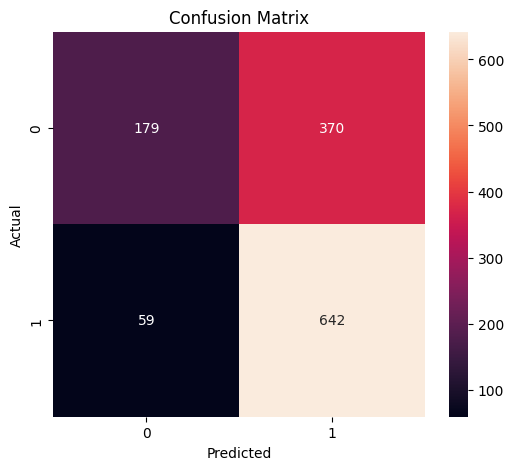

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

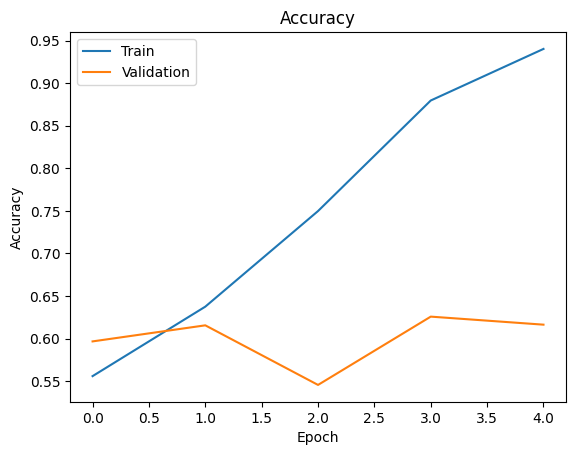

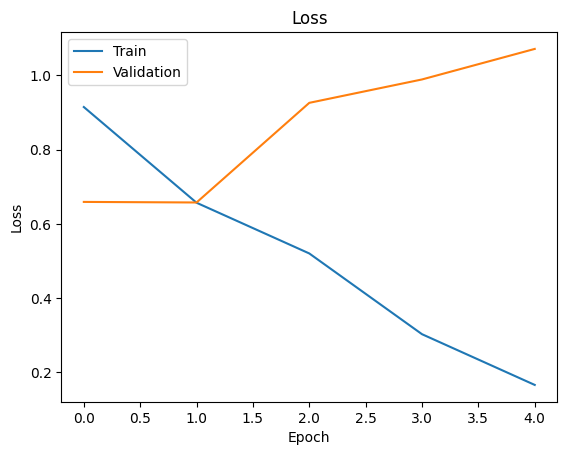

In [ ]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train","Validation"])

plt.show()

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend(["Train","Validation"])

plt.show()

In [ ]:
nrc = pd.read_csv("NRC-Emotion-Lexicon-Wordlevel-v0.92.txt",sep="\t",header=None,names=["word", "emotion", "association"])
nrc = nrc[nrc["association"] == 1]

emotion_dict = {}
emotion_labels = ['anger','anticipation','disgust','fear','joy','sadness','surprise','trust','positive','negative']

for _, row in nrc.iterrows():
    word = row["word"]
    emotion = row["emotion"]

    if word not in emotion_dict:
        emotion_dict[word] = []

    emotion_dict[word].append(emotion)

def extract_emotions(text):
    counts = Counter()
    words = str(text).split()

    for word in words:
        if word in emotion_dict:
            for emotion in emotion_dict[word]:
                if emotion in emotion_labels:
                    counts[emotion] += 1

    return [counts[e] for e in emotion_labels]

emotion_features_train = np.array(train_df["Combined_Text"].apply(extract_emotions).tolist())
emotion_features_valid = np.array(valid_df["Combined_Text"].apply(extract_emotions).tolist())
emotion_features_test = np.array(test_df["Combined_Text"].apply(extract_emotions).tolist())

emo_scaler = StandardScaler()

emotion_features_train = emo_scaler.fit_transform(emotion_features_train)
emotion_features_valid = emo_scaler.transform(emotion_features_valid)
emotion_features_test = emo_scaler.transform(emotion_features_test)

In [ ]:
text_input = Input(shape=(MAX_SEQUENCE_LENGTH,))
embedded = embedding_layer(text_input)

conv2 = Conv1D(128,2,activation="relu")(embedded)
conv3 = Conv1D(128,3,activation="relu")(embedded)
conv4 = Conv1D(128,4,activation="relu")(embedded)
conv5 = Conv1D(128,5,activation="relu")(embedded)
conv6 = Conv1D(128,6,activation="relu")(embedded)

pool2 = GlobalMaxPooling1D()(conv2)
pool3 = GlobalMaxPooling1D()(conv3)
pool4 = GlobalMaxPooling1D()(conv4)
pool5 = GlobalMaxPooling1D()(conv5)
pool6 = GlobalMaxPooling1D()(conv6)

text_features = Concatenate()([pool2, pool3, pool4, pool5, pool6])
text_features = Dense(128,activation='relu')(text_features)
text_features = BatchNormalization()(text_features)
text_features = Dropout(0.5)(text_features)

emotion_input = Input(shape=(10,))
emotion_features = Dense(32, activation="relu")(emotion_input)
emotion_features = BatchNormalization()(emotion_features)
emotion_features = Dropout(0.3)(emotion_features)

credit_input = Input(shape=(CREDIT_DIM,), name="credit_input")
cred = Dense(32, activation="relu",kernel_regularizer=l2(1e-4))(credit_input)
cred = BatchNormalization()(cred)
cred = Dropout(0.3)(cred)
cred = Dense(16, activation="relu")(cred)

merged = Concatenate()([text_features,cred,emotion_features])
merged = Dense(64,activation='relu')(merged)
merged = BatchNormalization()(merged)
merged = Dropout(0.5)(merged)
output = Dense(2,activation='softmax')(merged)

emotion_cnn = Model(inputs=[text_input, credit_input, emotion_input],outputs=output)

emotion_cnn.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3,weight_decay=1e-4,clipnorm=1.0),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

emotion_cnn.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 300)  │  4,560,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 99, 128)   │     76,928 │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 98, 128)   │    115,328 │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 97, 128)   │    153,728 │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 96, 128)   │    192,128 │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 95, 128)   │    230,528 │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_5[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_6[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_7[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_8[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_9[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ credit_input        │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 640)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │        192 │ credit_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │     82,048 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_7[0][0]     │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 5,424,242 (20.69 MB)

 Trainable params: 5,423,730 (20.69 MB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:
early_stop = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
checkpoint = ModelCheckpoint("best_emotion_cnn.keras",save_best_only=True,monitor="val_accuracy")
lr_plateau = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-6,verbose=1)

history = emotion_cnn.fit([X_train,X_train_credit,emotion_features_train],y_train,
                          validation_data=([X_valid,X_valid_credit,emotion_features_valid],y_valid),
                          epochs=20,
                          batch_size=32,
                          class_weight=class_weights,
                          callbacks=[early_stop,checkpoint,lr_plateau])

emotion_cnn.save("emotion_cnn.keras")

Epoch 1/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.5754 - loss: 0.8688 - val_accuracy: 0.5369 - val_loss: 1.3117 - learning_rate: 0.0010
Epoch 2/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6838 - loss: 0.6008 - val_accuracy: 0.6313 - val_loss: 0.6553 - learning_rate: 0.0010
Epoch 3/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8178 - loss: 0.4068 - val_accuracy: 0.6093 - val_loss: 0.9472 - learning_rate: 0.0010
Epoch 4/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9289 - loss: 0.1957 - val_accuracy: 0.6289 - val_loss: 1.2488 - learning_rate: 0.0010
Epoch 5/20
314/317 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9541 - loss: 0.1223
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
317/317 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9529 - loss: 0.1240 - val_accuracy: 0.5645 - val_loss: 1.7357 - learning_rate: 0.0010


In [ ]:
test_loss, test_acc = emotion_cnn.evaluate([X_test,X_test_credit,emotion_features_test],y_test)
print("Test Accuracy:", test_acc)

y_pred = emotion_cnn.predict([X_test,X_test_credit,emotion_features_test])
y_pred = np.argmax(y_pred, axis=1)

print(classification_report(y_test,y_pred))

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6360 - loss: 0.6440
Test Accuracy: 0.6359999775886536
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
              precision    recall  f1-score   support

           0       0.60      0.51      0.55       549
           1       0.66      0.73      0.69       701

    accuracy                           0.64      1250
   macro avg       0.63      0.62      0.62      1250
weighted avg       0.63      0.64      0.63      1250



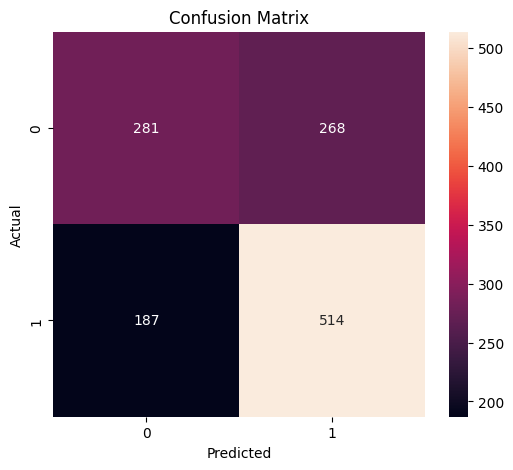

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

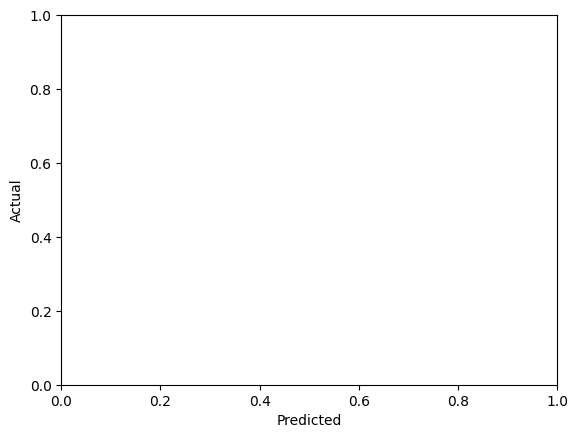

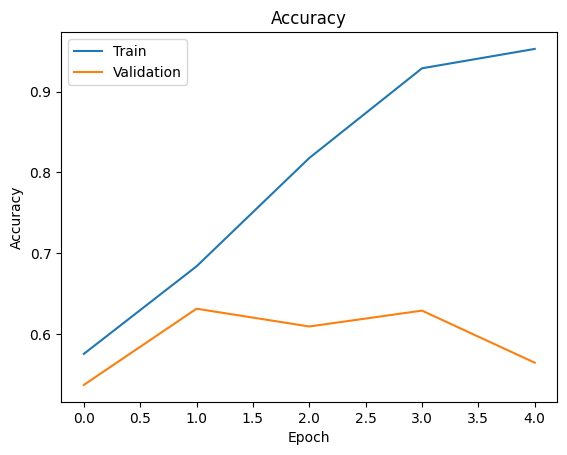

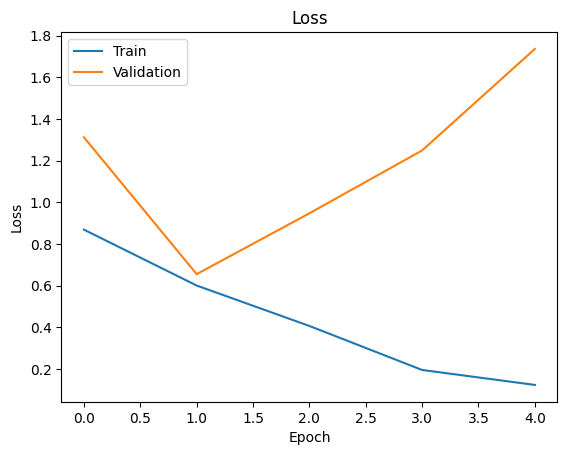

In [ ]:
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train","Validation"])

plt.show()

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend(["Train","Validation"])

plt.show()